# 03 · Analítica operativa: Citi Bike Nueva York, enero–marzo 2024

Consultas sobre el modelo estrella (`dw.fact_viaje` en columnstore). El trimestre es invierno: no sirve para hablar de estacionalidad anual, pero sí del crecimiento mes a mes, del uso de e-bikes y del desbalance diario de estaciones.

In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TABLAS = RAIZ / "reports" / "tablas"

def leer(nombre: str) -> pd.DataFrame:
    return pd.read_csv(TABLAS / f"{nombre}.csv")

def miles(x) -> str:
    return f"{x:,.0f}".replace(",", ".")

def dec(x, n=1) -> str:
    return f"{x:,.{n}f}".replace(",", "X").replace(".", ",").replace("X", ".")


## 1. Viajes por mes

In [2]:
mes_todo = leer('kpi_mensual')
print('Viajes del archivo de enero que empezaron el 31-12-2023:', miles(mes_todo.loc[mes_todo['anio'] == 2023, 'total_viajes'].sum()))
mes = mes_todo[mes_todo['anio'] == 2024].reset_index(drop=True)
mes['crec_vs_mes_anterior_%'] = (mes['total_viajes'].pct_change() * 100).round(1)
mes[['nombre_mes', 'total_viajes', 'crec_vs_mes_anterior_%', 'pct_electrica', 'pct_miembro', 'duracion_media_min', 'distancia_media_m']]

Viajes del archivo de enero que empezaron el 31-12-2023: 364


,nombre_mes,total_viajes,crec_vs_mes_anterior_%,pct_electrica,pct_miembro,duracion_media_min,distancia_media_m
0,Enero,1881782,NaN,64.24,89.02,10.82,1775
1,Febrero,2115986,12.4,64.42,88.12,11.01,1828
2,Marzo,2655855,25.5,64.69,84.17,12.30,1927


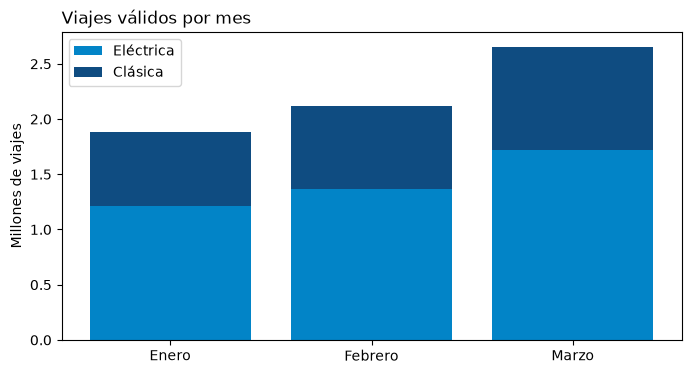

Trimestre: 6.653.987 viajes; e-bike 64,5 %; miembros 86,8 %


In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(mes['nombre_mes'], mes['viajes_electrica'] / 1e6, color='#0284c7', label='Eléctrica')
ax.bar(mes['nombre_mes'], mes['viajes_clasica'] / 1e6, bottom=mes['viajes_electrica'] / 1e6, color='#0f4c81', label='Clásica')
ax.set_ylabel('Millones de viajes'); ax.legend(); ax.set_title('Viajes válidos por mes', loc='left')
plt.show()
tot = mes_todo[['total_viajes', 'viajes_electrica', 'viajes_miembro']].sum()
print(f"Trimestre: {miles(tot['total_viajes'])} viajes; e-bike {dec(tot['viajes_electrica'] / tot['total_viajes'] * 100)} %; "
      f"miembros {dec(tot['viajes_miembro'] / tot['total_viajes'] * 100)} %")

## 2. Perfil horario: días laborales vs. fin de semana

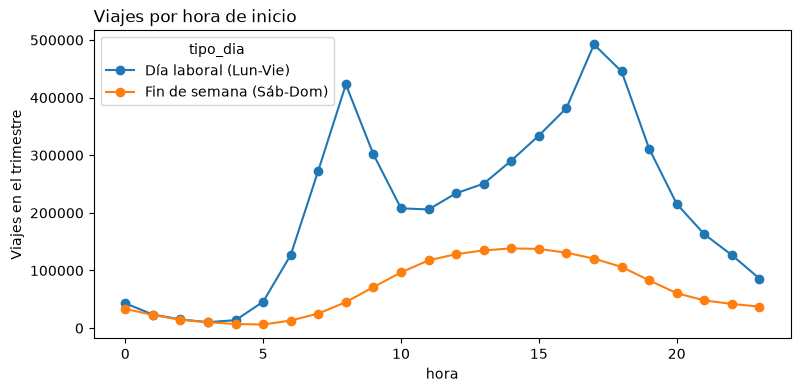

Día laboral (Lun-Vie): horas pico 17:00, 18:00; duración media 11,03 min
Fin de semana (Sáb-Dom): horas pico 14:00, 15:00; duración media 12,84 min


In [4]:
hor = leer('perfil_horario_semanal')
piv = hor.pivot(index='hora', columns='tipo_dia', values='total_viajes')
ax = piv.plot(figsize=(9, 4), marker='o')
ax.set_ylabel('Viajes en el trimestre'); ax.set_title('Viajes por hora de inicio', loc='left')
plt.show()
for tipo, sub in hor.groupby('tipo_dia'):
    top = sub.nlargest(2, 'total_viajes')
    dur = (sub['duracion_media_min'] * sub['total_viajes']).sum() / sub['total_viajes'].sum()
    print(f"{tipo}: horas pico {', '.join(f'{h:02d}:00' for h in top['hora'])}; duración media {dec(dur, 2)} min")

**Lectura:** los días laborales tienen dos picos (mañana y tarde) propios de viajes al trabajo; el fin de semana se concentra a media tarde y los viajes son más largos.

## 3. Desbalance de estaciones en la mañana

In [5]:
est = leer('desbalance_estaciones')
cols = ['estacion_id', 'estacion_nombre', 'total_salidas', 'total_llegadas', 'balance_neto_trimestre',
        'balance_neto_manana_6_10h', 'balance_neto_tarde_16_20h']
print('Se vacían en la mañana (más salidas que llegadas):')
display(est.nsmallest(5, 'balance_neto_manana_6_10h')[cols])
print('Se llenan en la mañana (más llegadas que salidas):')
display(est.nlargest(5, 'balance_neto_manana_6_10h')[cols])

Se vacían en la mañana (más salidas que llegadas):


,estacion_id,estacion_nombre,total_salidas,total_llegadas,balance_neto_trimestre,balance_neto_manana_6_10h,balance_neto_tarde_16_20h
17,6756.01,W 43 St & 10 Ave,16571,16299,-272,-3429,2878
45,5886.13,E 20 St & FDR Dr,14152,13322,-830,-3365,1538
100,6230.04,FDR Drive & E 35 St,11672,11531,-141,-2803,2200
9,6602.03,W 41 St & 8 Ave,19238,19239,1,-2671,1171
151,7183.03,Riverside Blvd & W 67 St,10033,9536,-497,-2651,1880


Se llenan en la mañana (más llegadas que salidas):


,estacion_id,estacion_nombre,total_salidas,total_llegadas,balance_neto_trimestre,balance_neto_manana_6_10h,balance_neto_tarde_16_20h
103,5470.12,North Moore St & Greenwich St,11397,11554,157,5994,-5903
2,6822.09,1 Ave & E 68 St,22376,22499,123,5361,-5081
42,6584.12,E 47 St & Park Ave,13905,14147,242,4875,-4231
342,5470.10,Greenwich St & Hubert St,4950,8058,3108,4586,-1797
294,6740.10,W 51 St & 6 Ave,5579,8760,3181,3753,-1264


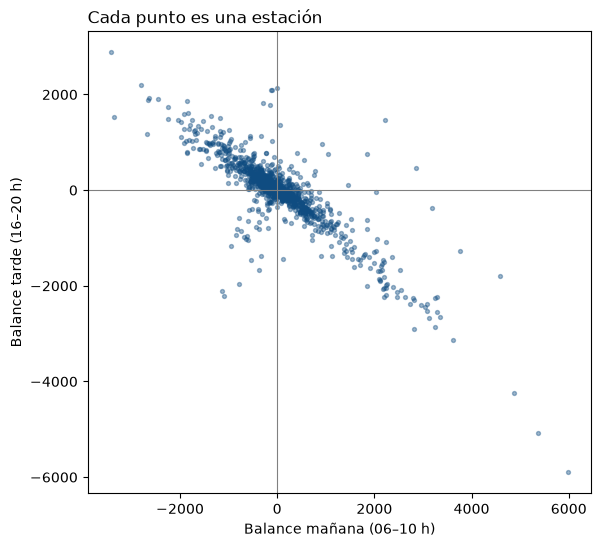

Correlación mañana vs. tarde: -0,84 (negativa = la tarde invierte el flujo de la mañana)


In [6]:
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(est['balance_neto_manana_6_10h'], est['balance_neto_tarde_16_20h'], s=8, alpha=0.4, color='#0f4c81')
ax.axhline(0, color='grey', lw=0.8); ax.axvline(0, color='grey', lw=0.8)
ax.set_xlabel('Balance mañana (06–10 h)'); ax.set_ylabel('Balance tarde (16–20 h)')
ax.set_title('Cada punto es una estación', loc='left')
plt.show()
r = est['balance_neto_manana_6_10h'].corr(est['balance_neto_tarde_16_20h'])
print(f'Correlación mañana vs. tarde: {dec(r, 2)} (negativa = la tarde invierte el flujo de la mañana)')

## 4. Rutas más frecuentes

In [7]:
rutas = leer('top_rutas')
rutas.head(10)[['origen_nombre', 'destino_nombre', 'viajes', 'pct_electrica', 'pct_miembro', 'duracion_media_min']]

,origen_nombre,destino_nombre,viajes,pct_electrica,pct_miembro,duracion_media_min
0,Central Park S & 6 Ave,Central Park S & 6 Ave,1891,66.84,11.48,34.90
1,7 Ave & Central Park South,7 Ave & Central Park South,1422,76.93,10.90,42.85
2,1 Ave & E 62 St,1 Ave & E 68 St,1299,36.10,98.61,3.65
3,W 21 St & 6 Ave,9 Ave & W 22 St,1213,43.20,97.03,4.28
4,E 48 St & 5 Ave,W 41 St & 8 Ave,1184,84.46,89.19,5.50
5,Amsterdam Ave & W 73 St,Amsterdam Ave & W 79 St,1176,55.87,92.60,2.58
6,E 77 St & 1 Ave,E 77 St & 3 Ave,1138,49.91,91.21,3.41
7,W 41 St & 8 Ave,E 48 St & 5 Ave,1071,80.30,90.38,5.38
8,Norfolk St & Broome St,Henry St & Grand St,1033,47.63,96.52,3.74
9,Forsyth St & Broome St,Delancey St & Eldridge St,982,3.36,99.90,3.58
